# T03 - Greeks y sensibilidades de opciones

---
Nombre: **Alan Jesús Hernández Soto**  
Carrera: **Ingeniería Financiera**  
Materia: **Simulación de Procesos Financieros**  
Tipo de trabajo: **Tarea**

---

## Opciones

Todas estas son vistas desde una posición *Long Call* y un activo (en este caso acción) que cotiza en $100.

| Opción | K | T (años) | Prima | Delta | Vega | Theta |
|---|---:|---:|---:|---:|---:|---:|
| A | 90 | 1/12 | 12 | 0.85 | 0.05 | -0.10 |
| B | 100 | 3/12 | 8 | 0.50 | 0.25 | -0.03 |
| C | 120 | 1 | 5 | 0.20 | 0.40 | -0.01 |

## Parte 1: Observación

Para comparar las opciones se usa el valor absoluto de cada sensibilidad. 

1. **Mayor sensibilidad al precio de la acción: Opción A.** Su Delta de 0.85 es el mayor. Aproximadamente, si la acción sube $1, su prima aumentaría $0.85, manteniendo los demás factores constantes.

2. **Mayor sensibilidad a volatilidad: Opción C.** Su Vega de 0.40 supera a B (0.25) y A (0.05). Un aumento de volatilidad aumenta mas el precio de la opción.

3. **Mayor deterioro por el tiempo: Opción A.** Tiene el Theta más negativo (-0.10).

4. **Comportamiento más parecido al de la acción: Opción A.** Su Delta de 0.85 está más cerca de 1. Por lo tanto los cambios entre el subyacente y la opción son muy similares.

5. **Mayor dependencia de un evento futuro importante: Opción C.** Tiene Delta bajo y Vega alto. Necesita un movimiento grande al alza o un aumento fuerte de volatilidad para ganar valore.

## Parte 2: Escenarios de mercado

La selección no depende solo del strike o de la prima. Los factores de sensibilidad son importantes.

### Escenario A: Aumento gradual durante los próximos meses sin cambio de volatilidad

**Compraría B y evitaría C.** B tiene Delta positivo de 0.50 y tres meses para capturar la subida gradual. A tiene más Delta, pero su vencimiento es de un mes. C tiene Delta bajo y strike 120; está diseñada para un cambio brusco.

### Escenario B: Anuncio en dos semanas y posible movimiento brusco, sin dirección clara

**Compraría C y evitaría A.** C tiene la Vega más alta y el menor deterioro temporal, por lo que es la call que más se beneficia si el mercado empieza a valorar mayor incertidumbre. A vence pronto, tiene Vega baja y pierde tiempo rápido. Teniendo en cuenta que las 3 son calls.

### Escenario C: precio muy estable

**Compraria C; evitaría A.** C tiene el Theta mas chico por lo tanto manteniendo todo constante este se deteriora mas con el tiempo a diferencia de A.

### Escenario D: caída significativa del precio

**Compraria C; evitaría A.** A tiene Delta 0.85, así que es la más expuesta a una baja de la acción. C tiene el Delta más bajo y sería la menos dañada dentro de las alternativas, teniendo en cuenta la obligación de adquirir una opción en posición larga.

### Escenario E: el mercado subestima la incertidumbre futura

**Compraría C y evitaría A.** C tiene la mayor Vega (0.40), por lo que un aumento de volatilidad implícita tiene mayor efecto sobre su prima. A tiene Vega de solo 0.05 y en poco tiempo

## Parte 3: aproximación con Greeks y valuación de la call

Se parte de una call con K = 100, r = 5% y vencimiento en octubre. En mayo su valor es V0 = 6.8887. Los Greeks iniciales son Delta = 0.5977, Gamma = 0.02736, Vega = 0.2814 y Theta = -8.116 anualizado.



Importamos las librerías, fijamos los parámetros iniciales de la call y construimos la trayectoria mensual del precio, la volatilidad y el tiempo restante.

In [185]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

r = 0.05
K = 100
V0 = 6.8887
delta = 0.5977
gamma = 0.02736
vega = 0.2814      # valor por cada punto porcentual
theta = -8.116     # anualizado

datos = pd.DataFrame({
    'Mes': ['Mayo', 'Junio', 'Julio', 'Agosto', 'Septiembre', 'Octubre'],
    'Precio': [100, 102, 101, 105, 103, 110],
    'Volatilidad': [0.20, 0.25, 0.30, 0.28, 0.22, 0.20],
    'Tiempo restante': [6/12, 5/12, 4/12, 3/12, 2/12, 1/12],
})
datos

,Mes,Precio,Volatilidad,Tiempo restante
0,Mayo,100,0.20,0.500000
1,Junio,102,0.25,0.416667
2,Julio,101,0.30,0.333333
3,Agosto,105,0.28,0.250000
4,Septiembre,103,0.22,0.166667
5,Octubre,110,0.20,0.083333


Definimos una función de Monte Carlo que simula los precios al vencimiento y descuenta el payoff promedio de la call.

In [186]:
def precio_monte_carlo_call(s0, k, r, sigma, t, n_simulaciones):
    z = np.random.normal(0 , 1, n_simulaciones)
    precios_finales = s0 * np.exp((r - 0.5 * sigma**2) * t + sigma * np.sqrt(t) * z )
    payoffs = np.maximum(precios_finales - k, 0)
    return np.exp(-r * t) * payoffs.mean()

Calculamos los cambios mensuales en precio y volatilidad, y usamos los Greeks iniciales para aproximar de forma acumulada el valor de la call.

In [187]:
datos['dS'] = datos['Precio'].diff()
datos['dsig'] = datos['Volatilidad'].diff()
datos['Valor aproximado (Greeks)'] = np.nan
datos.loc[0, 'Valor aproximado (Greeks)'] = V0

for i in range(1, len(datos)):
    d_s = datos.loc[i, 'dS']
    d_sigma = datos.loc[i, 'dsig']
    cambio_valor = (delta * d_s + 0.5 * gamma * d_s**2 + vega * d_sigma + theta * (1 / 12) )
    datos.loc[i, 'Valor aproximado (Greeks)'] = ( datos.loc[i - 1, 'Valor aproximado (Greeks)'] + cambio_valor )

tabla_greeks = datos[['Mes', 'Precio', 'Volatilidad', 'dS', 'dsig', 'Valor aproximado (Greeks)']].copy() 
display(tabla_greeks)

,Mes,Precio,Volatilidad,dS,dsig,Valor aproximado (Greeks)
0,Mayo,100,0.20,NaN,NaN,6.888700
1,Junio,102,0.25,2.0,0.05,7.476557
2,Julio,101,0.30,-1.0,0.05,6.230273
3,Agosto,105,0.28,4.0,-0.02,8.157992
4,Septiembre,103,0.22,-2.0,-0.06,6.324095
5,Octubre,110,0.20,7.0,-0.02,10.496353


Definimos Black-Scholes y valuamos la call en cada mes para obtener una referencia de comparación.

In [188]:
def precio_black_scholes_call(s0, k, r, sigma, t):
    d1 = (np.log(s0 / k) + (r + 0.5 * sigma**2) * t) / (sigma * np.sqrt(t))
    d2 = d1 - sigma * np.sqrt(t)
    return s0 * norm.cdf(d1) - k * np.exp(-r * t) * norm.cdf(d2)

tabla_bs = datos.copy()
tabla_bs = tabla_bs.drop(columns=['Valor aproximado (Greeks)', 'dS', 'dsig'])
tabla_bs['Tiempo restante'] = [6/12, 5/12, 4/12, 3/12, 2/12, 1/12]
tabla_bs['Valor Black-Scholes'] = np.nan
tabla_bs.loc[0, 'Valor Black-Scholes'] = V0

for i in range(1, len(tabla_bs)):
    tabla_bs.loc[i,'Valor Black-Scholes'] = precio_black_scholes_call(tabla_bs.loc[i, 'Precio'], K, r, tabla_bs.loc[i, 'Volatilidad'], tabla_bs.loc[i, 'Tiempo restante'])
display(tabla_bs)

,Mes,Precio,Volatilidad,Tiempo restante,Valor Black-Scholes
0,Mayo,100,0.20,0.500000,6.888700
1,Junio,102,0.25,0.416667,8.662111
2,Julio,101,0.30,0.333333,8.286009
3,Agosto,105,0.28,0.250000,9.341809
4,Septiembre,103,0.22,0.166667,5.852960
5,Octubre,110,0.20,0.083333,10.520232


Reunimos ambas valuaciones y calculamos el error absoluto de la aproximación con Greeks frente a Black-Scholes.

In [189]:
datos['Valor Black-Scholes'] = tabla_bs['Valor Black-Scholes']
comparacion = datos[['Mes', 'Valor aproximado (Greeks)', 'Valor Black-Scholes']].copy()
comparacion['Error Absoluto'] = np.abs(comparacion['Valor aproximado (Greeks)'] - comparacion['Valor Black-Scholes'])
display(comparacion)

,Mes,Valor aproximado (Greeks),Valor Black-Scholes,Error Absoluto
0,Mayo,6.888700,6.888700,0.000000
1,Junio,7.476557,8.662111,1.185555
2,Julio,6.230273,8.286009,2.055736
3,Agosto,8.157992,9.341809,1.183817
4,Septiembre,6.324095,5.852960,0.471134
5,Octubre,10.496353,10.520232,0.023879


### Comparación solicitada

Graficamos ambas trayectorias de valor para visualizar sus diferencias a lo largo de los meses.

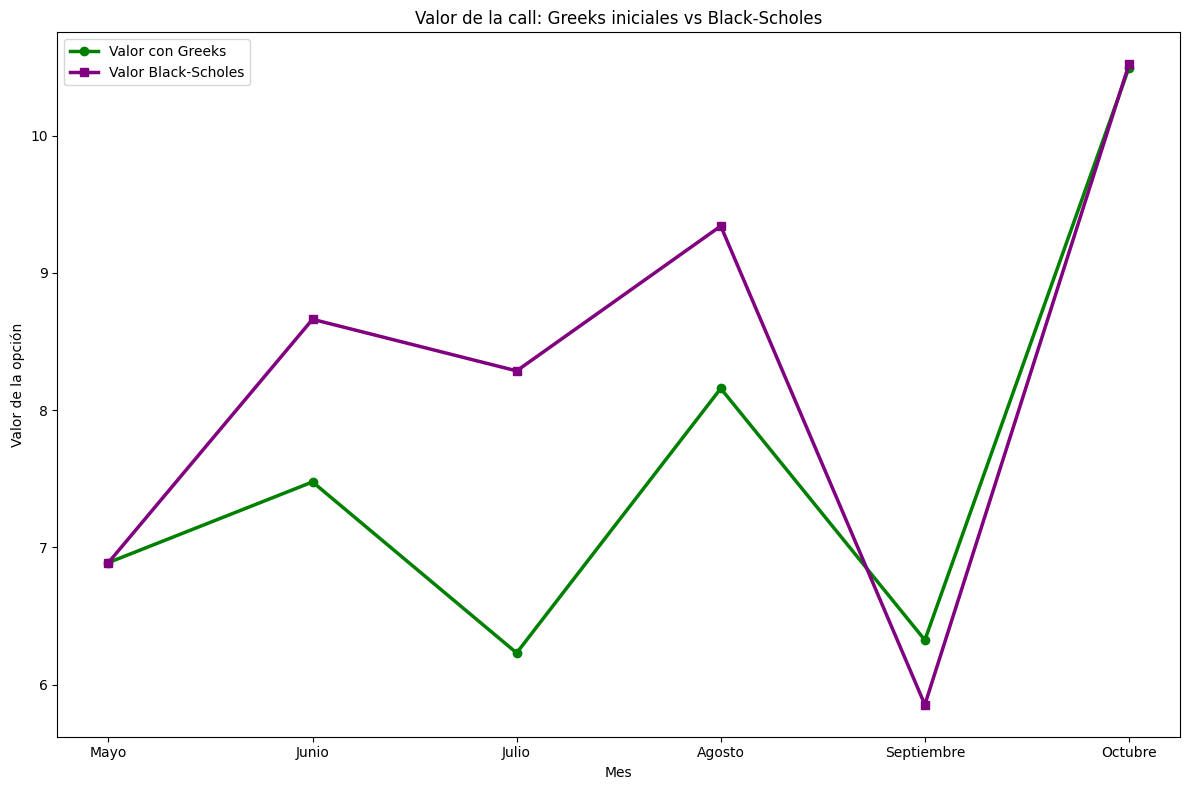

In [196]:
plt.figure(figsize=(12, 8))
plt.plot(datos['Mes'], datos['Valor aproximado (Greeks)'], marker='o', linewidth=2.5, color='green', label='Valor con Greeks' )
plt.plot(datos['Mes'], datos['Valor Black-Scholes'], marker='s', linewidth=2.5, color='purple', label='Valor Black-Scholes' )
plt.title('Valor de la call: Greeks iniciales vs Black-Scholes')
plt.xlabel('Mes')
plt.ylabel('Valor de la opción')
plt.legend()
plt.tight_layout()
plt.show()

## Interpretación de resultados

1. **¿Los Greeks iniciales describen con precisión toda la trayectoria?**  
No, parece ser que al final tienen un error muy pequeño pero en la trayectoria si hay diferencia.

2. **¿En qué mes apareció el error más grande?**  
En **Julio**, con un error absoluto aproximado de **2.0557**.

3. **¿Qué factor parece contribuir más al error?**  
Usar sensibilidades fijas mientras cambia el nivel de precio, la volatilidad y el tiempo restante.

4. **¿Por qué los Greeks funcionan mejor para movimientos pequeños que para movimientos grandes?**  
Con movimientos grandes, cambian la relación entre S y K, la volatilidad y el tiempo; por tanto, también cambian Delta, Gamma, Vega y Theta.

5. **Si la trayectoria fuera mucho más volátil, ¿esperarías errores menores? ¿Por qué?**  
No. Esperaría **errores mayores**, porque habría cambios más grandes en el precio y probablemente en la volatilidad.

6. **Conclusión**  
Los Greeks son útiles para entender riesgos y para estimar cambios cercanos al punto actual. Delta guía la exposición direccional; Vega mide el riesgo de volatilidad; Theta muestra el costo del tiempo. Sin embargo, para una trayectoria de varios meses conviene recalcular los Greeks o valuar de nuevo con Black-Scholes o Monte Carlo.